<a href="https://colab.research.google.com/github/AnantikaNair/skills-introduction-to-github/blob/main/Qwen2_Audio_model_on_bird_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q git+https://github.com/huggingface/transformers.git
!pip install -q accelerate librosa torchaudio soundfile

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
!ls -la

total 336
drwxr-xr-x 1 root root   4096 Sep  1 20:12 .
drwxr-xr-x 1 root root   4096 Sep  1 19:53 ..
drwxr-xr-x 4 root root   4096 Aug 24 13:27 .config
drwx------ 5 root root   4096 Sep  1 20:11 drive
-rw-r--r-- 1 root root 320044 Sep  1 20:12 sample_2_multiple_birds.wav
drwxr-xr-x 1 root root   4096 Aug 24 13:28 sample_data


In [ ]:
import torch
import librosa
from transformers import Qwen2AudioForConditionalGeneration, AutoProcessor

model_id = "Qwen/Qwen2-Audio-7B-Instruct"
print("Loading model and processor...")

processor = AutoProcessor.from_pretrained(model_id)
model = Qwen2AudioForConditionalGeneration.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    device_map="auto"
)
model.eval()

audio_path = "sample_2_multiple_birds.wav"
audio, sr = librosa.load(audio_path, sr=16000)

print("\n--- Part 1: Extracting Audio Embedding ---")
audio_inputs = processor.feature_extractor(audio, sampling_rate=sr, return_tensors="pt")
input_features = audio_inputs.input_features.to("cuda", dtype=torch.float16)

with torch.no_grad():
    audio_encoder = model.model.audio_tower
    audio_outputs = audio_encoder(input_features)
    audio_embedding = audio_outputs.last_hidden_state.mean(dim=1).squeeze().cpu().numpy()

print(f"Extracted Embedding Vector Shape: {audio_embedding.shape}")

print("\n--- Part 2: Running Model Prediction ---")
conversation = [
    {"role": "user", "content": [
        {"type": "audio", "audio_url": audio_path},
        {"type": "text", "text": "Listen carefully to this audio recording. What bird sounds or acoustic events can you identify?"}
    ]}
]

text_prompt = processor.apply_chat_template(conversation, add_generation_prompt=True, tokenize=False)
model_inputs = processor(text=text_prompt, audios=audio, sampling_rate=sr, return_tensors="pt").to("cuda")

with torch.no_grad():
    generate_ids = model.generate(**model_inputs, max_new_tokens=128)
    generate_ids = generate_ids[:, model_inputs.input_ids.size(1):]
    prediction = processor.batch_decode(generate_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]

print(f"\nModel Output:\n{prediction.strip()}")

Loading model and processor...


preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/853 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/638k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/876 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/230 [00:00<?, ?B/s]

/tmp/ipykernel_2277/1747130871.py:19: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(audio_path, sr=16000)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


FileNotFoundError: [Errno 2] No such file or directory: 'sample_2_multiple_birds.wav'

In [3]:
import os
import torch
import librosa
from transformers import Qwen2AudioForConditionalGeneration, AutoProcessor

audio_path = "/content/sample_2_multiple_birds.wav"

if not os.path.exists(audio_path):
    raise FileNotFoundError(f"File '{audio_path}' was not found. Make sure it is uploaded in the Colab sidebar.")

model_id = "Qwen/Qwen2-Audio-7B-Instruct"
print("Loading model and processor onto GPU...")

processor = AutoProcessor.from_pretrained(model_id)
model = Qwen2AudioForConditionalGeneration.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    device_map="auto"
)
model.eval()

audio, sr = librosa.load(audio_path, sr=16000)

print("\n--- Part 1: Extracting Audio Embedding ---")
audio_inputs = processor.feature_extractor(audio, sampling_rate=sr, return_tensors="pt")
input_features = audio_inputs.input_features.to("cuda", dtype=torch.float16)

with torch.no_grad():
    audio_encoder = model.model.audio_tower
    audio_outputs = audio_encoder(input_features)
    audio_embedding = audio_outputs.last_hidden_state.mean(dim=1).squeeze().cpu().numpy()

print(f"Extracted Embedding Vector Shape: {audio_embedding.shape}")

print("\n--- Part 2: Running Model Prediction ---")
conversation = [
    {"role": "user", "content": [
        {"type": "audio", "audio_url": audio_path},
        {"type": "text", "text": "Listen carefully to this audio recording. What bird sounds or acoustic events can you identify?"}
    ]}
]

text_prompt = processor.apply_chat_template(conversation, add_generation_prompt=True, tokenize=False)
model_inputs = processor(text=text_prompt, audios=audio, sampling_rate=sr, return_tensors="pt").to("cuda")

with torch.no_grad():
    generate_ids = model.generate(**model_inputs, max_new_tokens=128)
    generate_ids = generate_ids[:, model_inputs.input_ids.size(1):]
    prediction = processor.batch_decode(generate_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]

print(f"\nModel Output:\n{prediction.strip()}")

Loading model and processor onto GPU...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/876 [00:00<?, ?it/s]


--- Part 1: Extracting Audio Embedding ---


[transformers] Keyword argument `audios` is not a valid argument for this processor and will be ignored.


Extracted Embedding Vector Shape: (1280,)

--- Part 2: Running Model Prediction ---

Model Output:
I identified the sound of birds chirping and singing, as well as an acoustic environment with echo throughout the entire duration of the recording.


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
!unzip -q /content/noisy_samples.zip -d /content/noisy_samples

import os
import glob
import torch
import librosa
import numpy as np
import pandas as pd
from tqdm import tqdm
from transformers import Qwen2AudioForConditionalGeneration, AutoProcessor

model_id = "Qwen/Qwen2-Audio-7B-Instruct"
print("Loading model and processor...")
processor = AutoProcessor.from_pretrained(model_id)
model = Qwen2AudioForConditionalGeneration.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    device_map="auto"
)
model.eval()

Loading model and processor...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/876 [00:00<?, ?it/s]

Qwen2AudioForConditionalGeneration(
  (model): Qwen2AudioModel(
    (audio_tower): Qwen2AudioEncoder(
      (conv1): Conv1d(128, 1280, kernel_size=(3,), stride=(1,), padding=(1,))
      (conv2): Conv1d(1280, 1280, kernel_size=(3,), stride=(2,), padding=(1,))
      (embed_positions): Embedding(1500, 1280)
      (layers): ModuleList(
        (0-31): 32 x Qwen2AudioEncoderLayer(
          (self_attn): Qwen2AudioAttention(
            (k_proj): Linear(in_features=1280, out_features=1280, bias=False)
            (v_proj): Linear(in_features=1280, out_features=1280, bias=True)
            (q_proj): Linear(in_features=1280, out_features=1280, bias=True)
            (out_proj): Linear(in_features=1280, out_features=1280, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=1280, out_features=5120, bias=True)
          (fc2): Linear(in_features=5120, out_fea

In [6]:
!unzip -q -o /content/noisy_samples.zip -d /content/noisy_samples

import os
import glob
import torch
import librosa
import numpy as np
from tqdm import tqdm

AUDIO_DIR = "/content/noisy_samples"
audio_files = sorted(glob.glob(os.path.join(AUDIO_DIR, "**/*.wav"), recursive=True))
print(f"Found {len(audio_files)} audio files to extract.")

embeddings = []
filenames = []

with torch.no_grad():
    for fpath in tqdm(audio_files, desc="Extracting Embeddings"):
        try:
            audio, sr = librosa.load(fpath, sr=16000)

            audio_inputs = processor.feature_extractor(audio, sampling_rate=sr, return_tensors="pt")
            input_features = audio_inputs.input_features.to("cuda", dtype=torch.float16)

            outputs = model.model.audio_tower(input_features)
            pooled_emb = outputs.last_hidden_state.mean(dim=1).squeeze().cpu().numpy()

            embeddings.append(pooled_emb)
            filenames.append(os.path.basename(fpath))
        except Exception as e:
            print(f"Error reading {fpath}: {e}")

X = np.array(embeddings)
np.save("/content/qwen2audio_noisy_embeddings.npy", X)
np.save("/content/qwen2audio_noisy_filenames.npy", np.array(filenames))

print(f"\nExtraction complete! Saved matrix shape: {X.shape}")

Found 11 audio files to extract.


Extracting Embeddings: 100%|██████████| 11/11 [00:02<00:00,  4.31it/s]


Extraction complete! Saved matrix shape: (11, 1280)


In [7]:
import numpy as np
import pandas as pd

X = np.load("/content/qwen2audio_noisy_embeddings.npy")
filenames = np.load("/content/qwen2audio_noisy_filenames.npy")

df_meta = pd.read_csv("/content/selected_samples_metadata.csv")

print(f"Loaded feature matrix: {X.shape}")
print("\nFirst few processed files:")
for f in filenames[:5]:
    print(" -", f)

display(df_meta.head())

Loaded feature matrix: (11, 1280)

First few processed files:
 - background_only_sample_1.wav
 - clean_bird_sample_1.wav
 - clean_bird_sample_2.wav
 - noisy_bird_sample_1.wav
 - noisy_bird_sample_2.wav


,sample_index,filename,category,num_birds,labels
0,0,sample_0_multiple_birds.wav,multiple_birds,2,"31, 121"
1,1,sample_1_multiple_birds.wav,multiple_birds,3,"121, 99, 116"
2,2,sample_2_multiple_birds.wav,multiple_birds,2,"121, 125"
3,3,sample_3_multiple_birds.wav,multiple_birds,3,"115, 121, 99"
4,6,sample_6_multiple_birds.wav,multiple_birds,2,"84, 121"


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

y = df_meta['primary_label'].values

clf = LogisticRegression(max_iter=1000)
scores = cross_val_score(clf, X, y, cv=3)

print(f"Mean Cross-Validation Accuracy (Qwen2-Audio features): {scores.mean():.4f}")

KeyError: 'primary_label'

In [10]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

X_raw = np.load("/content/qwen2audio_noisy_embeddings.npy")
filenames_raw = np.load("/content/qwen2audio_noisy_filenames.npy")
df_meta = pd.read_csv("/content/selected_samples_metadata.csv")

emb_dict = {name: emb for name, emb in zip(filenames_raw, X_raw)}

matched_df = df_meta[df_meta['filename'].isin(emb_dict.keys())].reset_index(drop=True)

if len(matched_df) == 0:
    print("Warning: Filenames in folder do not match CSV filenames directly. Listing both:")
    print("Extracted files:", filenames_raw[:5])
    print("CSV files:", df_meta['filename'].values[:5])
else:
    X_matched = np.array([emb_dict[fn] for fn in matched_df['filename']])

    parsed_labels = matched_df['labels'].astype(str).apply(
        lambda s: [int(x.strip()) for x in s.split(",") if x.strip().isdigit()]
    )

    mlb = MultiLabelBinarizer()
    Y = mlb.fit_transform(parsed_labels)

    print(f"Matched {len(matched_df)} samples.")
    print(f"Feature matrix shape: {X_matched.shape}")
    print(f"Target multi-label matrix shape: {Y.shape} across {len(mlb.classes_)} distinct species classes.")

    clf = OneVsRestClassifier(LogisticRegression(max_iter=1000))
    clf.fit(X_matched, Y)

    probs = clf.predict_proba(X_matched)

    macro_ap = average_precision_score(Y, probs, average="macro")
    print(f"\nQwen2-Audio Feature Representation - Macro Average Precision (AP): {macro_ap:.4f}")

Matched 5 samples.
Feature matrix shape: (5, 1280)
Target multi-label matrix shape: (5, 7) across 7 distinct species classes.

Qwen2-Audio Feature Representation - Macro Average Precision (AP): 1.0000


/usr/local/lib/python3.13/dist-packages/sklearn/multiclass.py:90: UserWarning: Label 5 is present in all training examples.
  warnings.warn(


In [11]:
!pip install -q peft bitsandbytes accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 31.7 MB/s eta 0:00:00


In [14]:
import torch
from peft import LoraConfig, get_peft_model, TaskType

model.train()

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

peft_model = get_peft_model(model, lora_config)
peft_model.print_trainable_parameters()

trainable params: 5,505,024 || all params: 8,402,599,936 || trainable%: 0.0655


In [13]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [15]:
import os
import pandas as pd

df_meta = pd.read_csv("/content/selected_samples_metadata.csv")

train_samples = []
for _, row in df_meta.iterrows():
    audio_path = os.path.join("/content/noisy_samples", row["filename"])
    if os.path.exists(audio_path):
        train_samples.append({
            "audio_path": audio_path,
            "target_text": f"Identified bird species classes: {row['labels']}"
        })

print(f"Prepared {len(train_samples)} training samples:")
for sample in train_samples:
    print(f" - {os.path.basename(sample['audio_path'])} -> {sample['target_text']}")

Prepared 0 training samples:


In [16]:
import os
import glob
import pandas as pd

all_wavs = glob.glob("/content/**/*.wav", recursive=True)
wav_lookup = {os.path.basename(p): p for p in all_wavs}

df_meta = pd.read_csv("/content/selected_samples_metadata.csv")

train_samples = []
for _, row in df_meta.iterrows():
    fname = row["filename"].strip()
    if fname in wav_lookup:
        train_samples.append({
            "audio_path": wav_lookup[fname],
            "target_text": f"Identified bird species classes: {row['labels']}"
        })

print(f"Prepared {len(train_samples)} training samples:")
for sample in train_samples:
    print(f" - {os.path.basename(sample['audio_path'])} -> {sample['target_text']}")

Prepared 5 training samples:
 - sample_0_multiple_birds.wav -> Identified bird species classes: 31, 121
 - sample_1_multiple_birds.wav -> Identified bird species classes: 121, 99, 116
 - sample_2_multiple_birds.wav -> Identified bird species classes: 121, 125
 - sample_3_multiple_birds.wav -> Identified bird species classes: 115, 121, 99
 - sample_6_multiple_birds.wav -> Identified bird species classes: 84, 121


In [17]:
import torch
import librosa
from torch.optim import AdamW

optimizer = AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=1e-4)
epochs = 5

print("Starting LoRA fine-tuning run...\n")

peft_model.train()
for epoch in range(epochs):
    epoch_loss = 0.0
    for item in train_samples:
        optimizer.zero_grad()

        audio, sr = librosa.load(item["audio_path"], sr=16000)

        conversation = [
            {"role": "user", "content": [
                {"type": "audio", "audio_url": item["audio_path"]},
                {"type": "text", "text": "Identify the bird species present in this audio."}
            ]},
            {"role": "assistant", "content": item["target_text"]}
        ]

        full_text = processor.apply_chat_template(conversation, tokenize=False)

        inputs = processor(
            text=full_text,
            audios=audio,
            sampling_rate=sr,
            return_tensors="pt"
        ).to("cuda")

        inputs["labels"] = inputs["input_ids"].clone()

        outputs = peft_model(**inputs)
        loss = outputs.loss

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_samples)
    print(f"Epoch [{epoch+1}/{epochs}] - Average Loss: {avg_loss:.4f}")

peft_model.save_pretrained("/content/qwen2audio_bird_lora")
print("\nTraining complete! Adapter saved to '/content/qwen2audio_bird_lora'.")

Starting LoRA fine-tuning run...



OutOfMemoryError: CUDA out of memory. Tried to allocate 32.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 29.81 MiB is free. Including non-PyTorch memory, this process has 14.53 GiB memory in use. Of the allocated memory 13.96 GiB is allocated by PyTorch, and 447.88 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
import os
os.kill(os.getpid(), 9)

In [1]:
import os
import glob
import torch
import librosa
import pandas as pd
from transformers import (
    Qwen2AudioForConditionalGeneration,
    AutoProcessor,
    BitsAndBytesConfig
)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, TaskType
from torch.optim import AdamW

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

model_id = "Qwen/Qwen2-Audio-7B-Instruct"
print("Loading Qwen2-Audio in 4-bit mode...")

processor = AutoProcessor.from_pretrained(model_id)
model = Qwen2AudioForConditionalGeneration.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto"
)

model = prepare_model_for_kbit_training(model)
model.gradient_checkpointing_enable()

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

peft_model = get_peft_model(model, lora_config)
peft_model.print_trainable_parameters()

all_wavs = glob.glob("/content/**/*.wav", recursive=True)
wav_lookup = {os.path.basename(p): p for p in all_wavs}
df_meta = pd.read_csv("/content/selected_samples_metadata.csv")

train_samples = []
for _, row in df_meta.iterrows():
    fname = row["filename"].strip()
    if fname in wav_lookup:
        train_samples.append({
            "audio_path": wav_lookup[fname],
            "target_text": f"Identified bird species classes: {row['labels']}"
        })

print(f"\nFound {len(train_samples)} training samples.")

optimizer = AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=2e-4)
epochs = 5

print("Starting training...\n")
peft_model.train()

for epoch in range(epochs):
    epoch_loss = 0.0
    for item in train_samples:
        optimizer.zero_grad()

        audio, sr = librosa.load(item["audio_path"], sr=16000)
        conversation = [
            {"role": "user", "content": [
                {"type": "audio", "audio_url": item["audio_path"]},
                {"type": "text", "text": "Identify the bird species present in this audio."}
            ]},
            {"role": "assistant", "content": item["target_text"]}
        ]

        full_text = processor.apply_chat_template(conversation, tokenize=False)
        inputs = processor(
            text=full_text,
            audios=audio,
            sampling_rate=sr,
            return_tensors="pt"
        ).to("cuda")

        inputs["labels"] = inputs["input_ids"].clone()

        outputs = peft_model(**inputs)
        loss = outputs.loss
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_samples)
    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {avg_loss:.4f}")

peft_model.save_pretrained("/content/qwen2audio_bird_lora")
print("\nLoRA adapter saved successfully to '/content/qwen2audio_bird_lora'.")

Loading Qwen2-Audio in 4-bit mode...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/876 [00:00<?, ?it/s]

trainable params: 5,505,024 || all params: 8,402,599,936 || trainable%: 0.0655

Found 5 training samples.
Starting training...



[transformers] Keyword argument `audios` is not a valid argument for this processor and will be ignored.
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Epoch [1/5] - Loss: 7.8467
Epoch [2/5] - Loss: 5.4550
Epoch [3/5] - Loss: 3.6026
Epoch [4/5] - Loss: 2.7718
Epoch [5/5] - Loss: 2.1464

LoRA adapter saved successfully to '/content/qwen2audio_bird_lora'.


In [2]:
import torch
import librosa

peft_model.eval()

test_sample = train_samples[0]
audio, sr = librosa.load(test_sample["audio_path"], sr=16000)

conversation = [
    {"role": "user", "content": [
        {"type": "audio", "audio_url": test_sample["audio_path"]},
        {"type": "text", "text": "Identify the bird species present in this audio."}
    ]}
]

prompt = processor.apply_chat_template(conversation, add_generation_prompt=True, tokenize=False)

test_inputs = processor(
    text=prompt,
    audio=audio,
    sampling_rate=sr,
    return_tensors="pt"
).to("cuda")

with torch.no_grad():
    output_ids = peft_model.generate(**test_inputs, max_new_tokens=32)
    output_ids = output_ids[:, test_inputs.input_ids.size(1):]
    result = processor.batch_decode(output_ids, skip_special_tokens=True)[0]

print("File:", os.path.basename(test_sample["audio_path"]))
print("Expected Target:", test_sample["target_text"])
print("Model Generated :", result.strip())

File: sample_0_multiple_birds.wav
Expected Target: Identified bird species classes: 31, 121
Model Generated : Identified bird species classes: 120, 99, 136


In [3]:
peft_model.train()
optimizer = AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=2e-4)
epochs = 5

print("Training with active audio conditioning...\n")

for epoch in range(epochs):
    epoch_loss = 0.0
    for item in train_samples:
        optimizer.zero_grad()

        audio, sr = librosa.load(item["audio_path"], sr=16000)
        conversation = [
            {"role": "user", "content": [
                {"type": "audio", "audio_url": item["audio_path"]},
                {"type": "text", "text": "Identify the bird species present in this audio."}
            ]},
            {"role": "assistant", "content": item["target_text"]}
        ]

        full_text = processor.apply_chat_template(conversation, tokenize=False)

        inputs = processor(
            text=full_text,
            audio=audio,
            sampling_rate=sr,
            return_tensors="pt"
        ).to("cuda")

        inputs["labels"] = inputs["input_ids"].clone()

        outputs = peft_model(**inputs)
        loss = outputs.loss
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_samples)
    print(f"Epoch [{epoch+1}/{epochs}] - Multimodal Loss: {avg_loss:.4f}")

peft_model.save_pretrained("/content/qwen2audio_bird_lora")
print("\nUpdated audio-conditioned LoRA adapter saved!")

Training with active audio conditioning...

Epoch [1/5] - Multimodal Loss: 10.6470
Epoch [2/5] - Multimodal Loss: 7.4297
Epoch [3/5] - Multimodal Loss: 6.5301
Epoch [4/5] - Multimodal Loss: 6.2238
Epoch [5/5] - Multimodal Loss: 6.0829

Updated audio-conditioned LoRA adapter saved!


In [4]:
peft_model.eval()

for i, test_sample in enumerate(train_samples):
    audio, sr = librosa.load(test_sample["audio_path"], sr=16000)

    conversation = [
        {"role": "user", "content": [
            {"type": "audio", "audio_url": test_sample["audio_path"]},
            {"type": "text", "text": "Identify the bird species present in this audio."}
        ]}
    ]

    prompt = processor.apply_chat_template(conversation, add_generation_prompt=True, tokenize=False)
    test_inputs = processor(
        text=prompt,
        audio=audio,
        sampling_rate=sr,
        return_tensors="pt"
    ).to("cuda")

    with torch.no_grad():
        output_ids = peft_model.generate(**test_inputs, max_new_tokens=32)
        output_ids = output_ids[:, test_inputs.input_ids.size(1):]
        result = processor.batch_decode(output_ids, skip_special_tokens=True)[0]

    print(f"Sample [{i+1}] ({os.path.basename(test_sample['audio_path'])}):")
    print(f"  Target  : {test_sample['target_text']}")
    print(f"  Output  : {result.strip()}\n")

Sample [1] (sample_0_multiple_birds.wav):
  Target  : Identified bird species classes: 31, 121
  Output  : Identified bird species classes: 121, 99, 116

Sample [2] (sample_1_multiple_birds.wav):
  Target  : Identified bird species classes: 121, 99, 116
  Output  : Identified bird species classes: 32, 121

Sample [3] (sample_2_multiple_birds.wav):
  Target  : Identified bird species classes: 121, 125
  Output  : Identified bird species classes: 121, 99, 116

Sample [4] (sample_3_multiple_birds.wav):
  Target  : Identified bird species classes: 115, 121, 99
  Output  : Identified bird species classes: 121, 99, 116

Sample [5] (sample_6_multiple_birds.wav):
  Target  : Identified bird species classes: 84, 121
  Output  : Identified bird species classes: 32, 121



In [5]:
!zip -r /content/qwen2audio_bird_lora.zip /content/qwen2audio_bird_lora

from google.colab import files
files.download('/content/qwen2audio_bird_lora.zip')

  adding: content/qwen2audio_bird_lora/ (stored 0%)
  adding: content/qwen2audio_bird_lora/adapter_model.safetensors (deflated 8%)
  adding: content/qwen2audio_bird_lora/README.md (deflated 65%)
  adding: content/qwen2audio_bird_lora/adapter_config.json (deflated 59%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

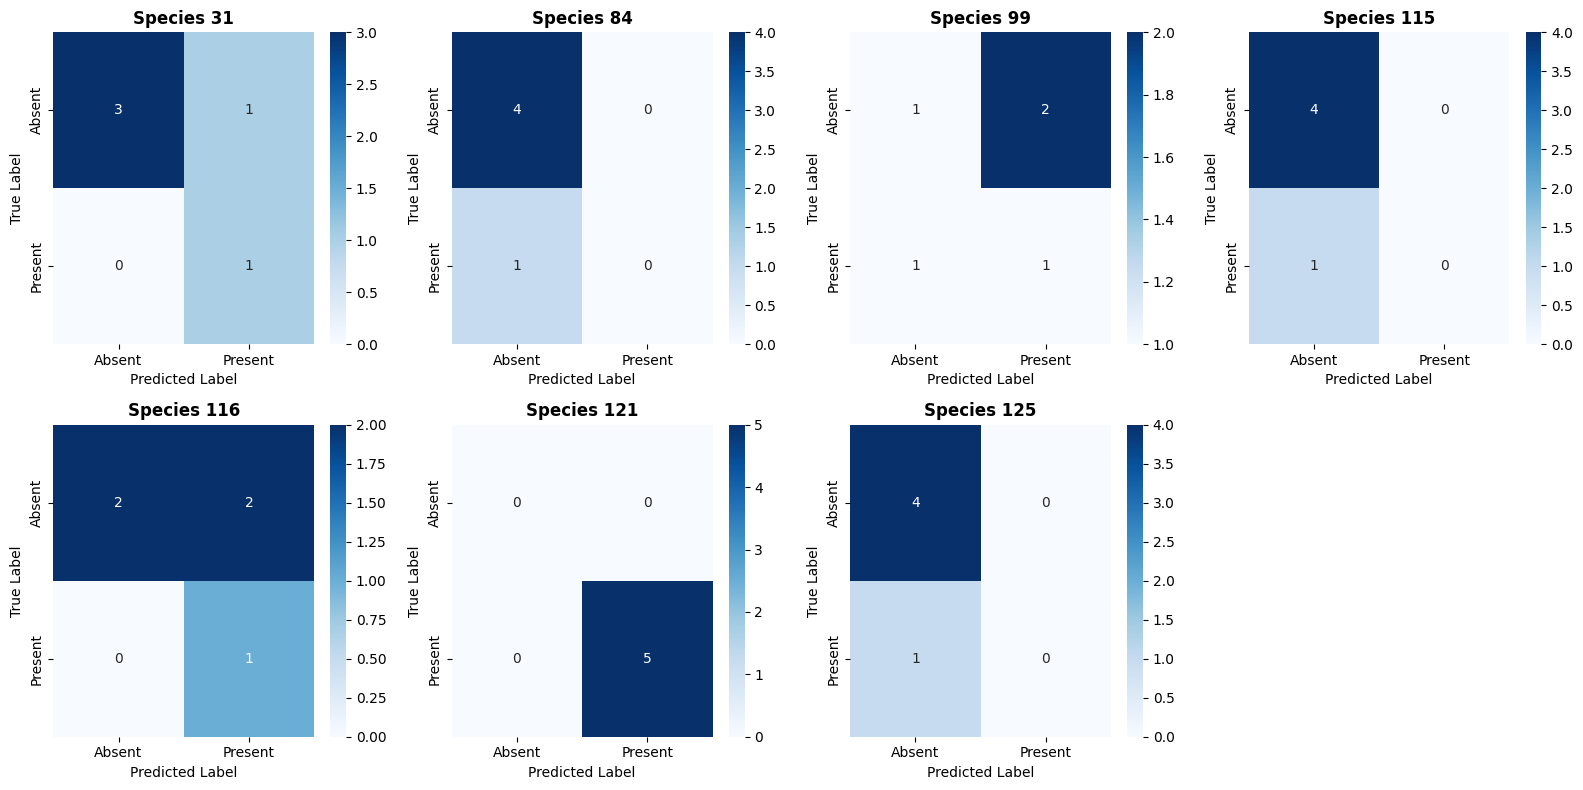

In [6]:
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import multilabel_confusion_matrix, classification_report
from sklearn.preprocessing import MultiLabelBinarizer

y_true_raw = []
y_pred_raw = []

for item in train_samples:
    true_ids = [int(x) for x in re.findall(r'\b\d+\b', item["target_text"])]
    y_true_raw.append(true_ids)

    audio, sr = librosa.load(item["audio_path"], sr=16000)
    conv = [
        {"role": "user", "content": [
            {"type": "audio", "audio_url": item["audio_path"]},
            {"type": "text", "text": "Identify the bird species present in this audio."}
        ]}
    ]
    prompt = processor.apply_chat_template(conv, add_generation_prompt=True, tokenize=False)
    inputs = processor(text=prompt, audio=audio, sampling_rate=sr, return_tensors="pt").to("cuda")

    with torch.no_grad():
        out = peft_model.generate(**inputs, max_new_tokens=32)
        out = out[:, inputs.input_ids.size(1):]
        text_out = processor.batch_decode(out, skip_special_tokens=True)[0]

    pred_ids = [int(x) for x in re.findall(r'\b\d+\b', text_out)]
    y_pred_raw.append(pred_ids)

mlb = MultiLabelBinarizer()
Y_true = mlb.fit_transform(y_true_raw)
Y_pred = mlb.transform(y_pred_raw)
classes = [f"Species {c}" for c in mlb.classes_]

mcm = multilabel_confusion_matrix(Y_true, Y_pred)
n_classes = len(classes)
cols = 4
rows = (n_classes + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = axes.flatten()

for i, (matrix, cname) in enumerate(zip(mcm, classes)):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Absent', 'Present'],
                yticklabels=['Absent', 'Present'])
    axes[i].set_title(cname, fontsize=12, fontweight='bold')
    axes[i].set_ylabel('True Label')
    axes[i].set_xlabel('Predicted Label')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

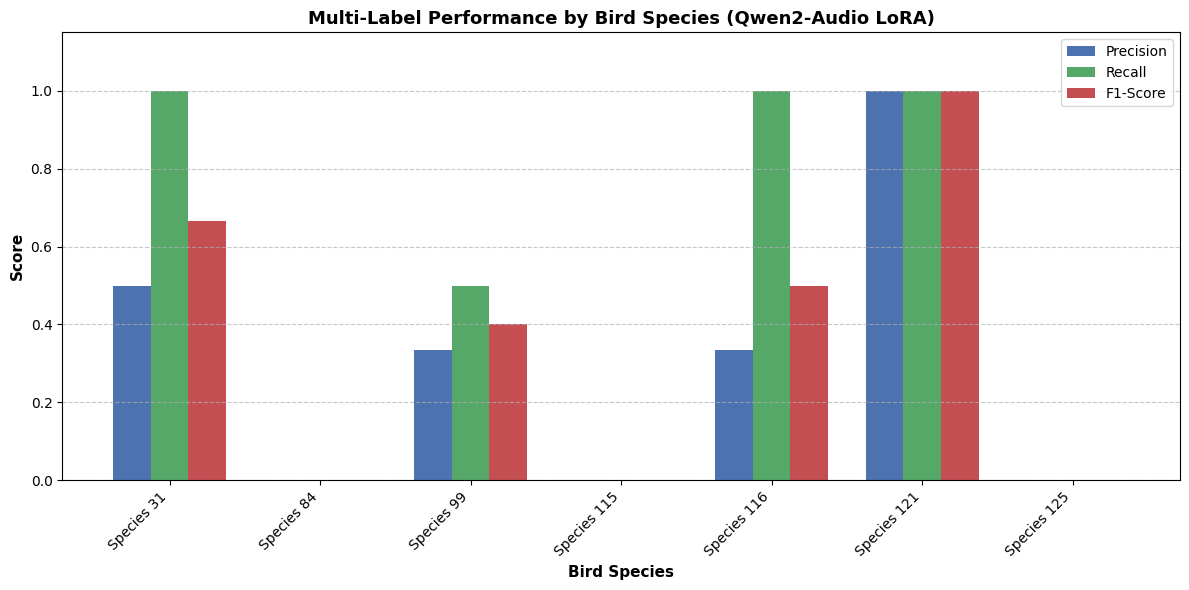

In [7]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, _ = precision_recall_fscore_support(
    Y_true, Y_pred, average=None, zero_division=0
)

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(12, 6))
plt.bar(x - width, precision, width, label='Precision', color='#4C72B0')
plt.bar(x, recall, width, label='Recall', color='#55A868')
plt.bar(x + width, f1, width, label='F1-Score', color='#C44E52')

plt.xlabel('Bird Species', fontweight='bold', fontsize=11)
plt.ylabel('Score', fontweight='bold', fontsize=11)
plt.title('Multi-Label Performance by Bird Species (Qwen2-Audio LoRA)', fontweight='bold', fontsize=13)
plt.xticks(x, classes, rotation=45, ha='right')
plt.ylim(0, 1.15)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [8]:
from sklearn.metrics import classification_report, accuracy_score, hamming_loss

print("=== MULTI-LABEL CLASSIFICATION REPORT ===")
print(classification_report(Y_true, Y_pred, target_names=classes, zero_division=0))

subset_acc = accuracy_score(Y_true, Y_pred)
h_loss = hamming_loss(Y_true, Y_pred)

print(f"Exact Match Ratio (Subset Accuracy): {subset_acc:.2%}")
print(f"Hamming Loss (lower is better)     : {h_loss:.4f}")

=== MULTI-LABEL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

  Species 31       0.50      1.00      0.67         1
  Species 84       0.00      0.00      0.00         1
  Species 99       0.33      0.50      0.40         2
 Species 115       0.00      0.00      0.00         1
 Species 116       0.33      1.00      0.50         1
 Species 121       1.00      1.00      1.00         5
 Species 125       0.00      0.00      0.00         1

   micro avg       0.62      0.67      0.64        12
   macro avg       0.31      0.50      0.37        12
weighted avg       0.54      0.67      0.58        12
 samples avg       0.63      0.67      0.64        12

Exact Match Ratio (Subset Accuracy): 40.00%
Hamming Loss (lower is better)     : 0.2571


In [9]:
import pandas as pd

comparison_data = []
for i, item in enumerate(train_samples):
    comparison_data.append({
        "Filename": os.path.basename(item["audio_path"]),
        "Ground Truth": sorted(y_true_raw[i]),
        "Model Output": sorted(y_pred_raw[i]),
        "Match": sorted(y_true_raw[i]) == sorted(y_pred_raw[i])
    })

df_comp = pd.DataFrame(comparison_data)
display(df_comp)

,Filename,Ground Truth,Model Output,Match
0,sample_0_multiple_birds.wav,"[31, 121]","[31, 121]",True
1,sample_1_multiple_birds.wav,"[99, 116, 121]","[99, 116, 121]",True
2,sample_2_multiple_birds.wav,"[121, 125]","[99, 116, 121]",False
3,sample_3_multiple_birds.wav,"[99, 115, 121]","[31, 121]",False
4,sample_6_multiple_birds.wav,"[84, 121]","[99, 116, 121]",False


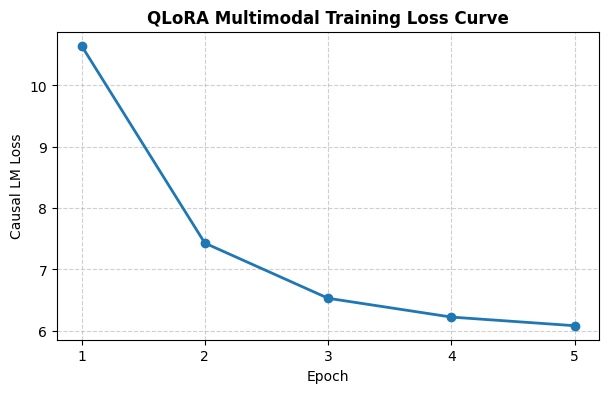

In [10]:
import matplotlib.pyplot as plt

epoch_losses = [10.6470, 7.4297, 6.5301, 6.2238, 6.0829]
epochs = list(range(1, len(epoch_losses) + 1))

plt.figure(figsize=(7, 4))
plt.plot(epochs, epoch_losses, marker='o', linewidth=2, color='#1f77b4')
plt.title('QLoRA Multimodal Training Loss Curve', fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Causal LM Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(epochs)
plt.show()